In [23]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans, SpectralClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import kneighbors_graph
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df= pd.read_csv('D:/Mall_Customers.csv')

In [27]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [31]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


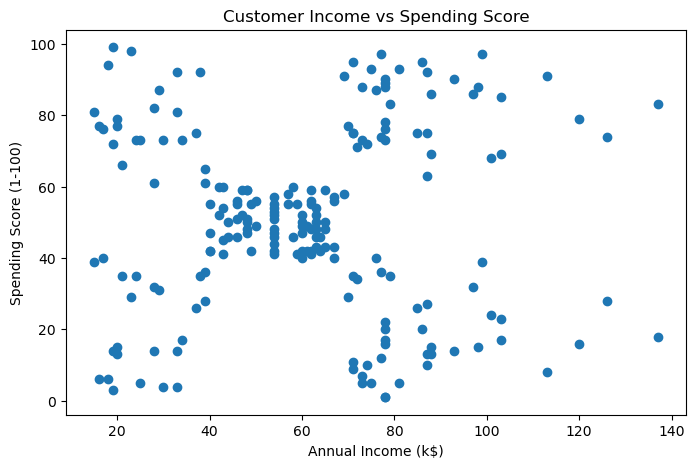

In [33]:

# Select the two features for our initial investigation
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Plot the relationship between income and spending
plt.figure(figsize=(8, 5))
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)']
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Income vs Spending Score')
plt.show()

In [35]:
print(X.mean())
print(X.std())

Annual Income (k$)        60.56
Spending Score (1-100)    50.20
dtype: float64
Annual Income (k$)        26.264721
Spending Score (1-100)    25.823522
dtype: float64


C:\Users\Home\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Home\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Home\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Home\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi

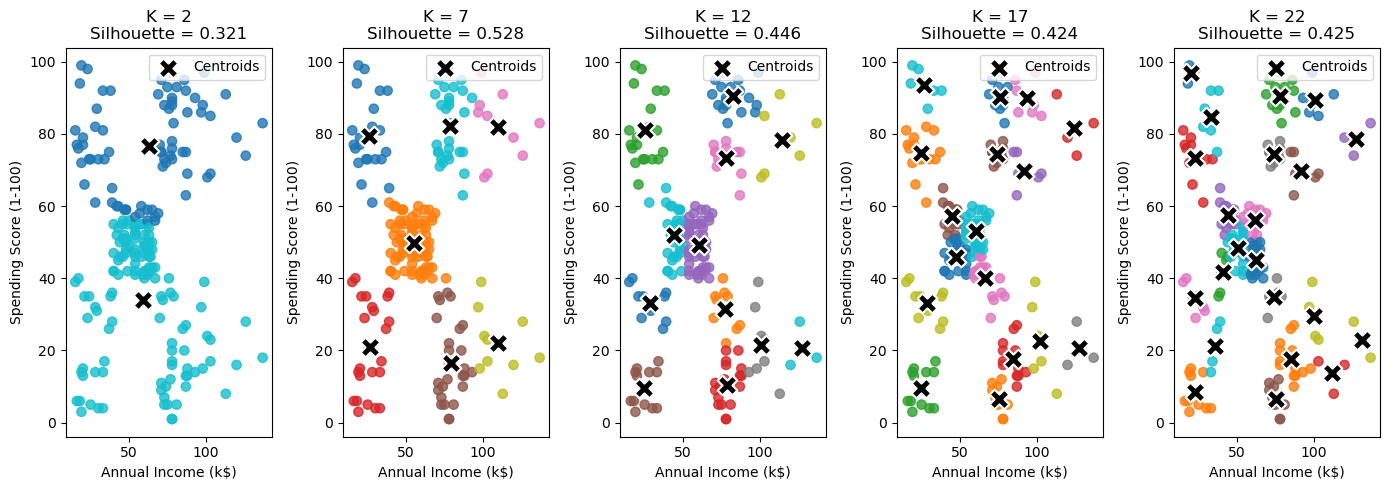

In [37]:

from sklearn.preprocessing import StandardScaler

# Select features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Values of K to compare
k_values = range(2, 25, 5)  

# Create one subplot for each K
fig, axes = plt.subplots(1, len(k_values), figsize=(14, 5))

for ax, k in zip(axes, k_values):

    # Fit K-Means
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    # Plot each customer, colored by assigned cluster
    ax.scatter(
        X['Annual Income (k$)'],
        X['Spending Score (1-100)'],
        c=labels,
        cmap='tab10',
        s=45,
        alpha=0.8
    )

    # Convert centroids back to the original feature scale
    centers = scaler.inverse_transform(model.cluster_centers_)

    # Show cluster centers
    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker='X',
        s=200,
        c='black',
        edgecolors='white',
        linewidths=1.5,
        label='Centroids'
    )

    ax.set_title(
        f'K = {k}\nSilhouette = {silhouette_score(X_scaled, labels):.3f}'
    )
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend()

plt.tight_layout()
plt.show()


In [39]:
# fitting selected model for k =5 for groupoing differnt type of customer basis observed pattern
k = 5  
model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
df_clustered = df.copy()
df_clustered['Cluster'] = model.fit_predict(X_scaled)

# Summarize each customer segment
profile = df_clustered.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending=('Spending Score (1-100)', 'mean')
).round(2)

print(profile)

         Customers  Average_Age  Average_Income  Average_Spending
Cluster                                                          
0               81        42.72           55.30             49.52
1               39        32.69           86.54             82.13
2               22        25.27           25.73             79.36
3               35        41.11           88.20             17.11
4               23        45.22           26.30             20.91


C:\Users\Home\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [49]:
# Maping cluster IDs to meaningful customer categories
segment_names = {
    0: 'Medium Income - Medium Spending',
    1: 'High Income - High Spending',
    2: 'Low Income - High Spending',
    3: 'High Income - Low Spending',
    4: 'Low Income - Low Speding'
}


df_clustered['Customer_Segment'] = (
    df_clustered['Cluster'].map(segment_names)
)



In [51]:
df_clustered

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Customer_Segment
0,1,Male,19,15,39,4,Low Income - Low Speding
1,2,Male,21,15,81,2,Low Income - High Spending
2,3,Female,20,16,6,4,Low Income - Low Speding
3,4,Female,23,16,77,2,Low Income - High Spending
4,5,Female,31,17,40,4,Low Income - Low Speding
...,...,...,...,...,...,...,...
195,196,Female,35,120,79,1,High Income - High Spending
196,197,Female,45,126,28,3,High Income - Low Spending
197,198,Male,32,126,74,1,High Income - High Spending
198,199,Male,32,137,18,3,High Income - Low Spending
